In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests as rq
import time

L'implantation des nouvelles méga-usines (batteries, hydrogène, data centers) se fait-elle de manière aveugle dans des bassins versants déjà condamnés à un épuisement de leurs nappes phréatiques ?

## Récupération des données

### Récupération des données sur les installations industrielles
On utilise l'API de Georisques pour récupérer les informations sur les usines.

In [3]:
#On récupère la liste des installations industrielles à l'échelle nationale sur le site de l'ICPE
url_icpe = "https://mapsref.brgm.fr/wxs/georisques/georisques_dl?&service=wfs&version=2.0.0&request=getfeature&typename=InstallationsClassees&outputformat=CSVTEXT"

fichier_icpe = rq.get(url_icpe)
lien_stockage_physique_icpe = "../../data/icpe.csv"

if fichier_icpe.status_code == 200:
    with open(lien_stockage_physique_icpe, "wb") as f:
        f.write(fichier_icpe.content)
    print("Fichier téléchargé.")
else:
    print("Erreur avec le téléchargement du fichier ICPE.")

Fichier téléchargé.


On a  136155 installations industrielles. Dont  104741 installations industrielles ICPE.
On ne garde que les  43744 installations industrielles pures.


<BarContainer object of 104 artists>

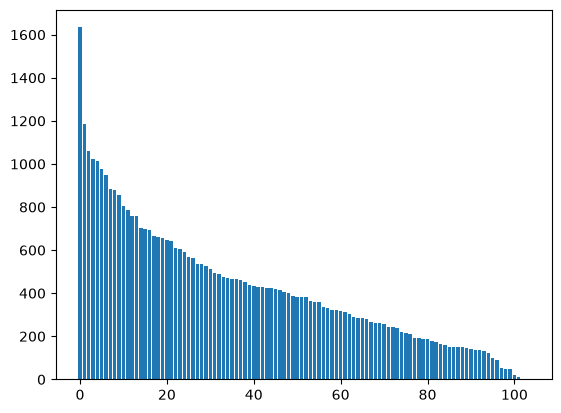

In [64]:
# On récupère donc la liste des installations industrielles
installations_indust = pd.read_csv(lien_stockage_physique_icpe, sep=";", encoding='utf-8')
print("On a ", installations_indust.shape[0], "installations industrielles.", end="")
installations_indust = installations_indust.loc[installations_indust["lib_regime"] != "Non ICPE"]
print(" Dont ", installations_indust.shape[0], "installations industrielles ICPE.")

#On veut garder uniquement les installations industrielles pures (pas l'agriculture et l'élevage par ex)
installations_indust = (installations_indust.loc[
    (installations_indust["industrie"] == 1)
    & (installations_indust["bovins"] == 0)
    & (installations_indust["porcs"] == 0)
    & (installations_indust["volailles"] == 0)
    & (installations_indust["eolienne"] == 0)
    ])
print("On ne garde que les ", installations_indust.shape[0], "installations industrielles pures.")

#On classe les départements qui ont le plus d'installations industrielles pour limiter la recherche (car les données sur Hub'eau sont trop volumineuses pour traiter la France entière)
classement_dpt = (installations_indust.groupby("num_dep")
    .size()
    .sort_values(ascending=False)
    )
plt.bar(range(classement_dpt.shape[0]), classement_dpt.values)

On va donc prendre le département qui contient le plus d'installations industrielles pour notre analyse.  
En effet, Hub'eau API nous donne un très grand volume de données et nous devons nous limiter dans notre recherche à quelques départements.  
Avec le graphique ci-dessus, on voit que le département 59 est de loin le plus grand centre industriel français.  
Nous nous concentrerons donc sur le département 59 pour la suite de l'analyse.  

In [65]:
departements_cibles = classement_dpt.index[0]
print("Département analysé : ", departements_cibles)

Département analysé :  59


### Récupération des données sur les nappes phréatiques du 59

L'API Hub'eau ne permet pas d'envoyer toutes les stations d'un coup.
Encore moins toutes les chroniques d'un coup.
Donc on sélectionne que les régions pour lesquelles on a vu qu'il y avait une grande concentration d'industrie

In [ ]:
assert 1==0

#On récupère les stations de mesure des nappes phréatiques sur le site Hubeau
url_stations = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/stations"
departements_cibles = "59"
stations = []

params = {"code_departement": dep, "size": 5000, "format": "json"}
fichier_stations = rq.get(url_stations, params=params)

if fichier_stations.status_code == 200:
    data = fichier_stations.json()
    stations.extend(data["data"])
    print("Fichier téléchargé. (", dep, ")")
else:
    print(fichier_stations.status_code)
    print("Erreur avec le téléchargement du fichier stations Hubeau. (", dep, ")")

stations = pd.DataFrame(stations)
stations.to_csv("../../data/stations_nappes.csv", encoding='utf-8')


AssertionError: 

Pour chaque station identifiée dans les départements contenant le plus d'industrie, on récupère les séries temporelles de niveau des nappes phréatiques

In [ ]:
#On récupère les volumes des nappes phréatiques pour chaque station
url_chroniques = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/chroniques"
chroniques = []

for code_bss in stations.loc[:, "code_bss"]:
    params = {"code_bss": code_bss, "size": 5000, "format": "json", "date_debut_mesure": "2015-01-01", "date_fin_mesure": "2026-10-01"}
    fichier_chroniques = rq.get(url_chroniques, params=params)

    if fichier_chroniques.status_code == 200:
        data = fichier_chroniques.json()
        chroniques.extend(data["data"])
        print("Fichier téléchargé. (", code_bss, ")")
    else:
        print(fichier_chroniques.status_code)
        print("Erreur avec le téléchargement du fichier stations Hubeau. (", code_bss, ")")

chroniques = pd.DataFrame(chroniques)
chroniques.to_csv("../../data/chroniques_nappes.csv", encoding='utf-8')

Fichier téléchargé. ( 00274X0010/F10 )
Fichier téléchargé. ( 00202A0131/F10 )
Fichier téléchargé. ( 00148A0012/F10 )
Fichier téléchargé. ( 00146C0077/F10 )
Fichier téléchargé. ( 00201C0530/PZ10 )
Fichier téléchargé. ( 00285X0478/PZ10 )
Fichier téléchargé. ( 00201B0020/F20 )
Fichier téléchargé. ( 00146D1978/LIL20 )
Fichier téléchargé. ( 00202A0401/PZ20 )
Fichier téléchargé. ( 00203B0377/PZ20 )
Fichier téléchargé. ( 00147C3289/PZ0 )


### Récupération des données sur les transports

In [ ]:
url_gares = "https://data.iledefrance-mobilites.fr/api/explore/v2.1/catalog/datasets/emplacement-des-gares-idf/exports/csv"
fichier_gares = rq.get(url_gares)
lien_stockage_physique_gares = "../../data/emplacement-des-gares-idf.csv"

if fichier_gares.status_code == 200:
    with open(lien_stockage_physique_gares, "wb") as f:
        f.write(fichier_gares.content)
    print("Fichier téléchargé.")
else:
    print("Erreur avec le téléchargement du fichier Gares.")

Fichier téléchargé.


In [ ]:
gares = pd.read_csv(lien_stockage_physique_gares, sep=';', encoding='utf-8')

## Nettoyage des données

### Nettoyage des données DVF

In [ ]:
print("Colonnes du DataFrame DVF :")
print(dvf.columns)
print("On ne sélectionne que les colonnes qui nous intéressent : ", end="")
colonnes_dvf = ["id_mutation", "date_mutation", "valeur_fonciere", "type_local", "surface_reelle_bati", "longitude", "latitude"]
print(colonnes_dvf)
dvf = dvf.loc[:, colonnes_dvf]

print("Types de logement : ")
dvf.loc[:, "type_local"].unique()
print("On ne garde que les maisons et les appartements (on ignore les locaux industriels par ex)")
dvf = dvf.loc[dvf.loc[:, "type_local"].isin(["Maison", "Appartement"]), :]

print("Lignes avec des na : ", end="")
nb_lignes_avec_na = dvf.loc[dvf['valeur_fonciere'].isnull() | dvf["surface_reelle_bati"].isnull() | dvf["longitude"].isnull() | dvf["latitude"].isnull(), "id_mutation"].count()
nb_lignes_total = dvf.shape[0]
print(f"{nb_lignes_avec_na/nb_lignes_total:.2%}")
print("Donc on élimine ces lignes")
dvf = dvf.loc[dvf['valeur_fonciere'].notnull() & dvf["surface_reelle_bati"].notnull() & dvf["longitude"].notnull() & dvf["latitude"].notnull(), :]
print("Il reste ", dvf.shape[0], " lignes")

Colonnes du DataFrame DVF :


NameError: name 'dvf' is not defined